# Manual testing of the EIOPA RFR DATABASE

The purpose of this workbook is to check if the implementation is correct. This is done by comparing two yield curves with the same maturities. One obtained from EIOPA directly and another calculated using the parameter. If the curves are sufficiently similar, then it is considered that the implementation is correct. 

Note that before November 2015, the curve names are different. This period is outside of scope for current testing.


For this framework, the tolerance is set at:

In [1]:
eps = 0.00001

## Functions and packages:

In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import datetime
%matplotlib notebook
%matplotlib inline
pd.options.display.max_rows = 150

In [3]:
def success_function(series_1, series_2, eps:float) -> bool:
    """
    Function that assesses if the comparison is good enough.
    """
    err = np.max(np.abs(series_1 - series_2))
    return err< eps, err
     
    #print(np.max(r_Target.values - one_curve_sized.loc[:,["spot_rate"]].values))

In [4]:
def filter_df_for_selection(df:pd.DataFrame, reference_date_str:str, country_str:str, is_va_str:str)-> pd.DataFrame:
    """
    Filters database for selected country, reference date and VA inclusion.
    """
    df_one = df[
        (df["reference_date"] == reference_date_str) &
        (df["country"] == country_str) &
        (df["curve_type"] == is_va_str)].copy()

    return df_one

In [5]:
def SWExtrapolate(M_Target, M_Obs, Qb, ufr, alpha):
# SWEXTRAPOLATE Interpolate or/and extrapolate rates for targeted maturities using a Smith-Wilson algorithm.
# out = SWExtrapolate(M_Target, M_Obs, Qb, ufr, alpha) calculates the rates for maturities specified in M_Target using the calibration vector b.
#
# Arguments: 
#    M_Target = k x 1 ndarray. Each element represents a bond maturity of interest. Ex. M_Target = [[1], [2], [3], [5]]
#    M_Obs =    n x 1 ndarray. Observed bond maturities used for calibrating the calibration vector b. Ex. M_Obs = [[1], [3]]
#    Qb =       n x 1 ndarray. Calibration vector calculated on observed bonds.
#    ufr =      1 x 1 floating number. Representing the ultimate forward rate.
#       Ex. ufr = 0.042
#    alpha =    1 x 1 floating number. Representing the convergence speed parameter alpha. Ex. alpha = 0.05
# 
#
# Returns:
#    k x 1 ndarray. Represents the targeted rates for a zero-coupon bond. Each rate belongs to a targeted zero-coupon bond with a maturity from T_Target. Ex. r = [0.0024; 0.0029; 0.0034; 0.0039]
#
# For more information see https://www.eiopa.europa.eu/sites/default/files/risk_free_interest_rate/12092019-technical_documentation.pdf

    def SWHeart(u, v, alpha):
    # SWHEART Calculate the heart of the Wilson function.
    # H = SWHeart(u, v, alpha) calculates the matrix H (Heart of the Wilson
    # function) for maturities specified by vectors u and v. The formula is
    # taken from the EIOPA technical specifications paragraph 132.
    #
    # Arguments:  
    #    u =     n_1 x 1 vector of maturities. Ex. u = [1; 3]
    #    v =     n_2 x 1 vector of maturities. Ex. v = [1; 2; 3; 5]
    #    alpha = 1 x 1 floating number representing the convergence speed parameter alpha. Ex. alpha = 0.05
    #
    # Returns:
    #    n_1 x n_2 matrix representing the Heart of the Wilson function for selected maturities and parameter alpha. H is calculated as in the paragraph 132 of the EIOPA documentation. 
    #
    # For more information see https://www.eiopa.europa.eu/sites/default/files/risk_free_interest_rate/12092019-technical_documentation.pdf

        u_Mat = np.tile(u, [v.size, 1]).transpose()
        v_Mat = np.tile(v, [u.size, 1])
        return 0.5 * (alpha * (u_Mat + v_Mat) + np.exp(-alpha * (u_Mat + v_Mat)) - alpha * np.absolute(u_Mat-v_Mat) - np.exp(-alpha * np.absolute(u_Mat-v_Mat))); # Heart of the Wilson function from paragraph 132

    H = SWHeart(M_Target, M_Obs, alpha) # Heart of the Wilson function from paragraph 132
    p = np.exp(-np.log(1+ufr)* M_Target) + np.diag(np.exp(-np.log(1+ufr) * M_Target)) @ H @ Qb # Discount pricing function for targeted maturities from paragraph 147
    return p ** (-1/ M_Target) -1 # Convert obtained prices to rates and return prices

## Import of results

In [6]:
current_dir = os.getcwd()

In [7]:
data_dir = current_dir + "\\data"

In [8]:
param_path = os.path.join(data_dir,"curve_parameters.csv")

In [9]:
curves_path = os.path.join(data_dir,"yield_curves.csv")

In [10]:
Qb_path = os.path.join(data_dir,"qb_vectors.csv")

In [11]:
all_params = pd.read_csv(param_path, header=0)

In [12]:
all_curves = pd.read_csv(curves_path, header=0)

In [13]:
all_Qb = pd.read_csv(Qb_path, header=0)

## Run selection

In this section, the user can define a specific run.

In [14]:
reference_date_str = "2023-05-31"
reference_year = int(reference_date_str[:4])
reference_month = int(reference_date_str[5:7])
reference_day = int(reference_date_str[8:])

In [15]:
country = "SI"

In [16]:
is_va_str = "with_VA"

In [17]:
num_years = 150

In [18]:
M_Target =  np.transpose(np.arange(1,num_years))

## Data transformation

In this section, the large tables are filtered and data is transformed into the correct shape.

### Periods

In [19]:
start = datetime.date(reference_year+1, reference_month, reference_day)
end = datetime.date(reference_year+num_years-1, reference_month, reference_day)

### Qb

In [20]:
all_Qb.head()

,reference_date,curve_type,country,term_index,qb_value
0,2014-12-31,no_VA,AT,1.0,-1.939468
1,2014-12-31,no_VA,AT,2.0,0.897682
2,2014-12-31,no_VA,AT,3.0,-0.309434
3,2014-12-31,no_VA,AT,4.0,0.380559
4,2014-12-31,no_VA,AT,5.0,-0.007954


In [21]:
one_Qb = filter_df_for_selection(all_Qb, reference_date_str, country, is_va_str)

In [22]:
Qb = one_Qb.loc[:,"qb_value"].values

In [23]:
one_Qb.head()

,reference_date,curve_type,country,term_index,qb_value
305988,2023-05-31,with_VA,SI,1.0,-10.723324
305989,2023-05-31,with_VA,SI,2.0,2.431863
305990,2023-05-31,with_VA,SI,3.0,0.247369
305991,2023-05-31,with_VA,SI,4.0,1.278669
305992,2023-05-31,with_VA,SI,5.0,0.285183


In [24]:
display(Qb)

array([-1.07233243e+01,  2.43186304e+00,  2.47369204e-01,  1.27866865e+00,
        2.85182949e-01, -5.97697307e-01,  9.85473470e-01, -1.70080859e+00,
        4.27494700e+00, -8.37552090e+00,  9.50610776e+00, -3.90286000e+00,
       -6.90907082e-03, -1.21081774e-02, -1.06828883e+00,  2.09720776e-02,
        5.18732776e-02, -7.29232627e-02,  3.86860702e-01,  3.63031049e-01])

### Parameters

In [25]:
all_params.head()

,reference_date,curve_type,country,instrument_type,coupon_freq,llp,convergence,ufr,alpha,cra,va
0,2014-12-31,no_VA,AT,SWP,1.0,20.0,40.0,4.2,0.129489,10.0,0.0
1,2014-12-31,no_VA,AUD,SWP,2.0,30.0,40.0,4.2,0.103482,35.0,0.0
2,2014-12-31,no_VA,BE,SWP,1.0,20.0,40.0,4.2,0.129489,10.0,0.0
3,2014-12-31,no_VA,BGN,SWP,1.0,20.0,40.0,4.2,0.130023,15.0,0.0
4,2014-12-31,no_VA,BRL,GVT,0.0,10.0,50.0,5.2,0.138381,35.0,0.0


In [26]:
one_param = filter_df_for_selection(all_params, reference_date_str, country, is_va_str)

In [27]:
display(one_param)

,reference_date,curve_type,country,instrument_type,coupon_freq,llp,convergence,ufr,alpha,cra,va
10804,2023-05-31,with_VA,SI,EXT,1.0,20.0,40.0,3.45,0.110654,10.0,19.0


In [28]:
ufr = one_param.loc[:,"ufr"].values[0]/100

In [29]:
alpha = one_param.loc[:,"alpha"].values[0]

In [30]:
print(f"The parameters are: ufr: {ufr} and alpha: {alpha}")

The parameters are: ufr: 0.0345 and alpha: 0.110654


### Yield curve

In [31]:
periods_date = pd.date_range(start = start, end = end, periods = M_Target.shape[0], unit=None)

In [32]:
M_Obs = np.transpose(np.array(list(one_Qb.loc[:,"term_index"].values)))

In [33]:
display(M_Obs)

array([ 1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11., 12., 13.,
       14., 15., 16., 17., 18., 19., 20.])

In [34]:
r_Target = SWExtrapolate(M_Target,M_Obs, Qb, ufr, alpha)
r_Target = pd.DataFrame(r_Target,columns=['Recalculated rates'], index = M_Target)

In [35]:
r_Target.head()

,Recalculated rates
1,0.039290
2,0.035903
3,0.033418
4,0.031861
5,0.031004


## Import curve

In [36]:
all_curves.head()

,reference_date,curve_type,country,term_index,spot_rate
0,2014-12-31,no_VA,AT,1.0,0.00062
1,2014-12-31,no_VA,AT,2.0,0.00075
2,2014-12-31,no_VA,AT,3.0,0.00120
3,2014-12-31,no_VA,AT,4.0,0.00184
4,2014-12-31,no_VA,AT,5.0,0.00261


In [37]:
one_curve = filter_df_for_selection(all_curves, reference_date_str, country, is_va_str)

In [38]:
one_curve_sized = one_curve.iloc[:periods_date.shape[0],:]

In [39]:
one_curve.head()

,reference_date,curve_type,country,term_index,spot_rate
1620600,2023-05-31,with_VA,SI,1.0,0.03929
1620601,2023-05-31,with_VA,SI,2.0,0.03590
1620602,2023-05-31,with_VA,SI,3.0,0.03342
1620603,2023-05-31,with_VA,SI,4.0,0.03186
1620604,2023-05-31,with_VA,SI,5.0,0.03100


## Compare calculated curves with the ones from the database

This subsection creates a visual comparison of both curves. The user can inspect if the curve is correct and how good is the fit.

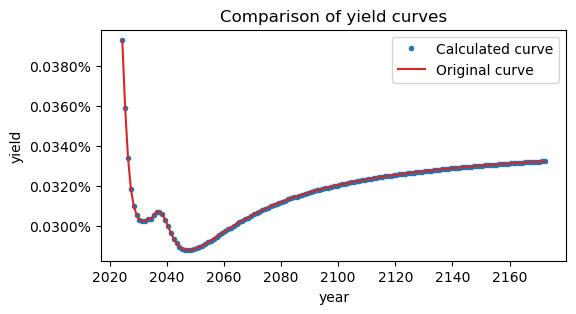

In [40]:
fig, ax1 = plt.subplots(1,1)
ax1.plot(periods_date, r_Target.values, color='tab:blue',label="Calculated curve", marker='.', linestyle='')
ax1.plot(periods_date, one_curve_sized.loc[:,["spot_rate"]].values, color='tab:red',label="Original curve",  linestyle='-')

ax1.set_ylabel("yield")
ax1.set_title('Comparison of yield curves')
ax1.set_xlabel("year")
ax1.legend()
ax1.yaxis.set_major_formatter(mtick.PercentFormatter())
fig.set_figwidth(6)
fig.set_figheight(3)
plt.show()

In [41]:
test, error = success_function(r_Target.values, one_curve_sized.loc[:,["spot_rate"]].values, eps)

print(f"Comparison between curves status, test passed: {test}.")
print(f"The norm of the difference is: {str(error)}.")

Comparison between curves status, test passed: True.
The norm of the difference is: 4.9989331113303725e-06.


## All together


In [42]:
curve_types = ["no_VA", "with_VA"]
list_countries = ["AT","AU","BE","BG","CA","CH","CN","CO","CY","CZ","DE","DK","EE","ES","EU","FI","FR","GR","HK","HR","HU","IE","IS","IT","JP","LI","LT","LU","LV","MT","NL","NO","PL","PT","RO","SE","SI","SK","TW","UK","US"]
#list_dates = ["2014-12-31","2015-01-31","2015-02-28","2015-03-31","2015-04-30","2015-05-31","2015-06-30","2015-07-31","2015-08-31","2015-09-30","2015-10-31","2015-11-30","2015-12-31","2016-01-31","2016-02-29","2016-03-31","2016-04-30","2016-05-31","2016-06-30","2016-07-31","2016-08-31","2016-09-30","2016-10-31","2016-11-30","2016-12-31","2017-01-31","2017-02-28","2017-03-31","2017-04-30","2017-05-31","2017-06-30","2017-07-31","2017-08-31","2017-09-30","2017-10-31","2017-11-30","2017-12-31","2018-01-31","2018-02-28","2018-03-31","2018-04-30","2018-05-31","2018-06-30","2018-07-31","2018-08-31","2018-09-30","2018-10-31","2018-11-30","2018-12-31","2019-01-31","2019-02-28","2019-03-31","2019-04-30","2019-05-31","2019-06-30","2019-07-31","2019-08-31","2019-09-30","2019-10-31","2019-11-30","2019-12-31","2020-01-31","2020-02-29","2020-03-31","2020-04-30","2020-05-31","2020-06-30","2020-07-31","2020-08-31","2020-09-30","2020-10-31","2020-11-30","2020-12-31","2021-01-31","2021-02-28","2021-03-31","2021-04-30","2021-05-31","2021-06-30","2021-07-31","2021-08-31","2021-09-30","2021-10-31","2021-11-30","2021-12-31","2022-01-31","2022-02-28","2022-03-31","2022-04-30","2022-05-31","2022-06-30","2022-07-31","2022-08-31","2022-09-30","2022-10-31","2022-11-30","2022-12-31","2023-01-31","2023-02-28","2023-03-31","2023-04-30","2023-05-31","2023-06-30","2023-07-31","2023-08-31","2023-09-30","2023-10-31","2023-11-30","2023-12-31","2024-01-31","2024-02-29","2024-03-31","2024-04-30","2024-05-31","2024-06-30","2024-07-31","2024-08-31","2024-09-30","2024-10-31","2024-11-30","2024-12-31","2025-01-31","2025-02-28","2025-03-31","2025-04-30","2025-05-31","2025-06-30","2025-07-31","2025-08-31","2025-09-30","2025-10-31","2025-11-30","2025-12-31","2026-01-31","2026-02-28"]
list_dates = ["2015-11-30","2015-12-31","2016-01-31","2016-02-29","2016-03-31","2016-04-30","2016-05-31","2016-06-30","2016-07-31","2016-08-31","2016-09-30","2016-10-31","2016-11-30","2016-12-31","2017-01-31","2017-02-28","2017-03-31","2017-04-30","2017-05-31","2017-06-30","2017-07-31","2017-08-31","2017-09-30","2017-10-31","2017-11-30","2017-12-31","2018-01-31","2018-02-28","2018-03-31","2018-04-30","2018-05-31","2018-06-30","2018-07-31","2018-08-31","2018-09-30","2018-10-31","2018-11-30","2018-12-31","2019-01-31","2019-02-28","2019-03-31","2019-04-30","2019-05-31","2019-06-30","2019-07-31","2019-08-31","2019-09-30","2019-10-31","2019-11-30","2019-12-31","2020-01-31","2020-02-29","2020-03-31","2020-04-30","2020-05-31","2020-06-30","2020-07-31","2020-08-31","2020-09-30","2020-10-31","2020-11-30","2020-12-31","2021-01-31","2021-02-28","2021-03-31","2021-04-30","2021-05-31","2021-06-30","2021-07-31","2021-08-31","2021-09-30","2021-10-31","2021-11-30","2021-12-31","2022-01-31","2022-02-28","2022-03-31","2022-04-30","2022-05-31","2022-06-30","2022-07-31","2022-08-31","2022-09-30","2022-10-31","2022-11-30","2022-12-31","2023-01-31","2023-02-28","2023-03-31","2023-04-30","2023-05-31","2023-06-30","2023-07-31","2023-08-31","2023-09-30","2023-10-31","2023-11-30","2023-12-31","2024-01-31","2024-02-29","2024-03-31","2024-04-30","2024-05-31","2024-06-30","2024-07-31","2024-08-31","2024-09-30","2024-10-31","2024-11-30","2024-12-31","2025-01-31","2025-02-28","2025-03-31","2025-04-30","2025-05-31","2025-06-30","2025-07-31","2025-08-31","2025-09-30","2025-10-31","2025-11-30","2025-12-31","2026-01-31","2026-02-28","2026-03-31","2026-04-30","2026-05-31","2026-06-30"]
num_years = 150

In [43]:
M_Target =  np.transpose(np.arange(1, num_years))

for curve_type in curve_types:
    for country_tmp in list_countries:
        for reference_date_str_tmp in list_dates:
            reference_year = int(reference_date_str_tmp[:4])
            reference_month = int(reference_date_str_tmp[5:7])
            reference_day = int(reference_date_str_tmp[8:])
            
            one_Qb = filter_df_for_selection(all_Qb, reference_date_str_tmp, country_tmp, curve_type)
            one_param = filter_df_for_selection(all_params, reference_date_str_tmp, country_tmp, curve_type)
            Qb = one_Qb.loc[:,"qb_value"].values
            ufr = one_param.loc[:,"ufr"].values[0]/100
            alpha = one_param.loc[:,"alpha"].values[0]
    
            M_Obs = np.transpose(np.array(list(one_Qb.loc[:,"term_index"].values)))
            r_Target = SWExtrapolate(M_Target,M_Obs, Qb, ufr, alpha)
            r_Target = pd.DataFrame(r_Target,columns=['Recalculated rates'], index = M_Target)
            
            one_curve = filter_df_for_selection(all_curves, reference_date_str_tmp, country_tmp, curve_type)
            one_curve_sized = one_curve.iloc[:(num_years-1),:]
    
            test, error = success_function(r_Target.values, one_curve_sized.loc[:,["spot_rate"]].values, eps)
            if not test:
                print(country_tmp)
                print(reference_date_str_tmp)
                print(error)